# Example calculation of Skewness-voxel
This script calculates the center of mass of POSS cages to compute their skewness-voxel.
Details on the skewness-voxel method are found in the publication.

This uses the `segment` class to get the POSS cages.
More details on segments can be found in the `0_preprocessing/extract_segment.py`.

In [1]:
from vast_pea.lammps_traj import trajectory
from vast_pea.lammps_segments import segment
from vast_pea.masses import PCFF_MASSES, types_to_masses
from vast_pea.computers import compute_skewness_voxel

import matplotlib.pyplot as plt

## Get the POSS cages center of mass

### Read the trajectory

In [ ]:
traj = trajectory(path="../../data/BER/",
                  pattern="oaps_ber_325K.dump", # we need one of the nanocomposite system
                  filter_type=False, # read all atoms since we need them to extract segments
                  filter=False,
                  restore=False,
                  verbose=True
                  )

	File list contains 1 files
	Reading trajectory...
	Trajectory done!


### Calculate POSS cage segments

In [ ]:
# a list of the types in the system in the order of their atom type id
types = ['c',  # 1
         'c1',  # 2
         'c2',  # 3
         'c3',  # 4
         'cp',  # 5
         'h',   # 6
         'hc',  # 7
         'hn',  # 8
         'ho2', # 9
         'nn',  # 10
         'oc',  # 11
         'oh',  # 12
         'osi', # 13
         's1',  # 14
         'sio', # 15
        ]
# transfer that list of types to a list of masses
masses = types_to_masses(types, PCFF_MASSES)

# define the segments
segment_identifiers = [{ # here we only have 1 type of segments, but many can be defined (check extract_segments.py)
    'end_types':[15,13], # types of the identifiable beginning and end of the segment
    'end_offset':[0,0], # offset to the end_types for the actual beginning and end of the segment
    'com_range':["0:2","4:7","9","10","12:15","17","18","20","23:26"], # atom ids to include in the center of mass calculation of the segment relative to the beginning of the segment
    'exclusivity_offset':26 # offset in atom id to not scan for a new segment after the end of the previous segment
    }]

# calculate segments
poss_cages = segment(traj=traj,
                     mass_list=masses,
                     identifiers=segment_identifiers,
                     verbose=True
                     )

	Calculating segments!


### Make sure segments are properly defined (optional)

In [ ]:
# output the center of mass of segments and all atoms in the trajectory to a LAMMPS dump file.
# It is fairly slow, so it only outputs the first timestep.
poss_cages.dump_unwrapped_coms_and_atoms(path="../../data/BER/",
                                         name="oaps_ber_325K_poss-cages.dump",
                                         traj=traj
                                         )

## Calculate Skewness-voxel

In [ ]:
skewness, q_count = compute_skewness_voxel(coms=poss_cages.get_coms(), # centers of mass of POSS cages
                                           bounds=traj.get_bounds(), # bounds of the trajectory used to define the simulation box
                                           vox_per_dim=3, # number of voxels per dimension used to split the simulation box
                                           verbose=True # print information about simulation and voxel volume/length
                                           )

Simulation cell volume: 528638.16±68.46, length: 80.86±0.00
Voxel volume: 19579.19±2.54, length: 26.95±0.00
Simulation cell - voxels volume: 0.00000±0.00000, length: 0.00000±0.00000


### Plot skewness

[]

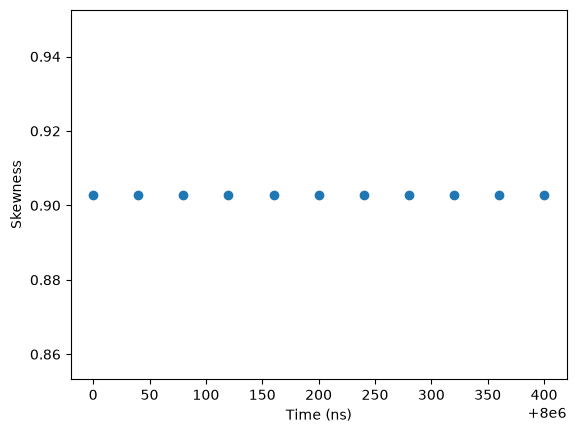

In [7]:
plt.plot(traj.timesteps, skewness, 'o')
plt.xlabel('Time (ns)')
plt.ylabel('Skewness')
plt.plot()

### Plot Nqi distribution

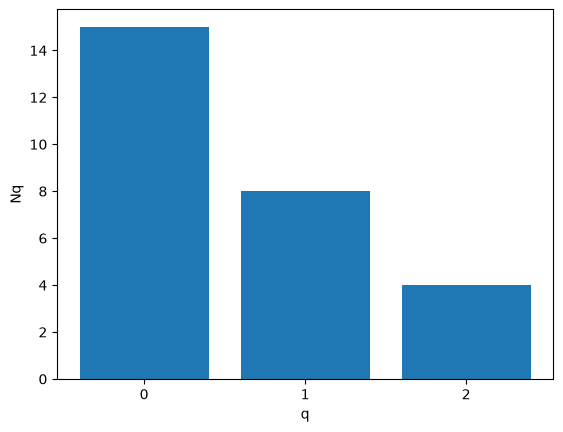

In [40]:
plt.bar(q_count.q, q_count.mean(dim='ts'))
plt.xlabel('q')
plt.ylabel('Nq')
plt.xticks(q_count.q)
plt.show()